In [1]:
import sys
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(_root / "scripts"))

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from glacier_utils import PROC, TAB, set_style, save_fig
set_style()

gdf = gpd.read_file(PROC / "nepal_glaciers.gpkg", layer="glaciers")
core = gdf[gdf["centroid_in_nepal"]].copy()          # rgi_id stays a normal column here

SECTORS = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
# Sector k is centred on k*45 degrees and spans +/-22.5 degrees (matches RGI aspect_sec, verified in notebook 01)
core["sector"] = (((core["aspect_deg"] + 22.5) % 360) // 45).astype(int)
assert ((core["sector"] + 1) == core["aspect_sec"]).all(), "sector mismatch with aspect_sec"

# Groups used in the tests
core["size_grp"] = pd.cut(core["area_km2"], [0, 0.5, 1, 5, 10, np.inf],
                          labels=["<0.5", "0.5–1", "1–5", "5–10", "≥10"], right=False)
core["elev_grp"], elev_edges = pd.qcut(core["zmed_m"], 3, labels=["low", "middle", "high"], retbins=True)
print(f"{len(core):,} glaciers | median-elevation tercile edges: {elev_edges.round(0)} m")

4,480 glaciers | median-elevation tercile edges: [2654. 5285. 5629. 8116.] m


In [2]:
by_sector = core.groupby("sector").agg(n=("rgi_id", "size"), area_km2=("area_km2", "sum"))
by_sector.index = SECTORS
by_sector["pct_glaciers"] = 100 * by_sector["n"] / by_sector["n"].sum()
by_sector["pct_area"] = 100 * by_sector["area_km2"] / by_sector["area_km2"].sum()
print(by_sector.round(1).to_string())
by_sector.round(2).to_csv(TAB / "aspect_by_sector.csv", index_label="sector")

def circ_mean(deg, w=None):
    """Weighted circular mean direction (degrees) and mean resultant length R (0 = uniform, 1 = identical)."""
    th = np.radians(deg)
    w = np.ones_like(th) if w is None else np.asarray(w)
    C, S = (w * np.cos(th)).sum(), (w * np.sin(th)).sum()
    return np.degrees(np.arctan2(S, C)) % 360, np.hypot(C, S) / w.sum()

for label, w in (("Per glacier (count)", None), ("Area-weighted", core["area_km2"])):
    m, R = circ_mean(core["aspect_deg"], w)
    print(f"{label:20s}: mean aspect = {m:5.1f} deg | R = {R:.3f}")

north = by_sector.loc[["NW", "N", "NE"], ["pct_glaciers", "pct_area"]].sum()
south = by_sector.loc[["SE", "S", "SW"], ["pct_glaciers", "pct_area"]].sum()
print(f"\nNW+N+NE: {north['pct_glaciers']:.1f}% of glaciers, {north['pct_area']:.1f}% of area")
print(f"SE+S+SW: {south['pct_glaciers']:.1f}% of glaciers, {south['pct_area']:.1f}% of area")

      n  area_km2  pct_glaciers  pct_area
N   760     784.5          17.0      18.5
NE  560     406.9          12.5       9.6
E   415     409.9           9.3       9.7
SE  410     353.3           9.2       8.3
S   550     644.4          12.3      15.2
SW  569     585.2          12.7      13.8
W   554     459.2          12.4      10.8
NW  662     601.3          14.8      14.2
Per glacier (count) : mean aspect = 319.1 deg | R = 0.114
Area-weighted       : mean aspect = 301.1 deg | R = 0.105

NW+N+NE: 44.2% of glaciers, 42.2% of area
SE+S+SW: 34.1% of glaciers, 37.3% of area


Saved outputs/figures/04_aspect_rose.png and .svg


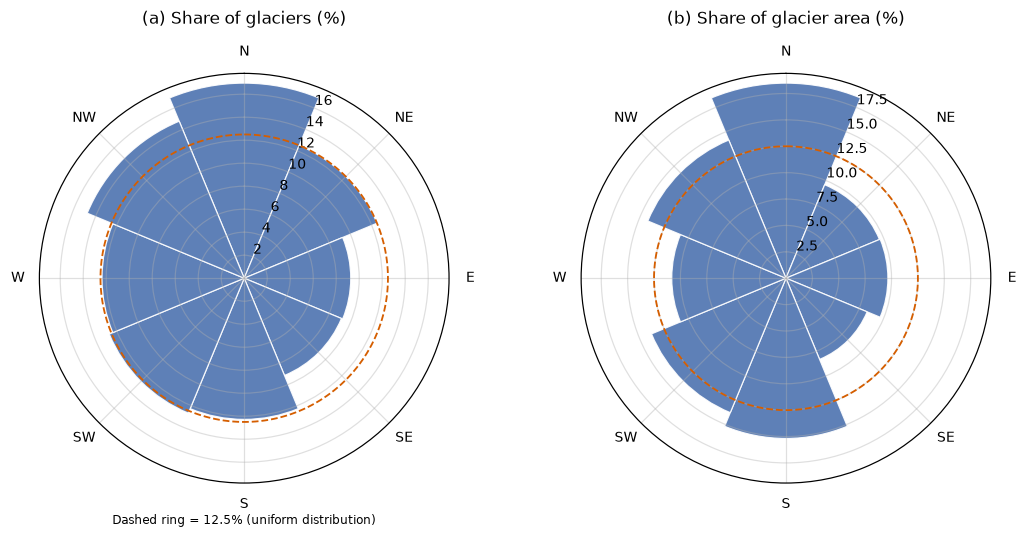

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), subplot_kw={"projection": "polar"})
theta = np.radians(np.arange(8) * 45)

for ax, col, title in zip(axes, ["pct_glaciers", "pct_area"],
                          ["(a) Share of glaciers (%)", "(b) Share of glacier area (%)"]):
    ax.bar(theta, by_sector[col], width=np.radians(45), color="#4C72B0",
           edgecolor="white", linewidth=0.8, alpha=0.9)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)                       # clockwise, compass convention
    ax.set_xticks(theta, SECTORS)
    ax.axhline(12.5, color="none")                   # placeholder so the radial range is not clipped
    ax.set_rlabel_position(22.5)
    ax.set_title(title, pad=14)
    ax.grid(alpha=0.4)
    # Dashed ring marks 12.5%: what a perfectly uniform distribution would give for each of 8 sectors
    ax.plot(np.linspace(0, 2 * np.pi, 200), np.full(200, 12.5), color="#D55E00", ls="--", lw=1.2)

axes[0].text(0.5, -0.1, "Dashed ring = 12.5% (uniform distribution)", transform=axes[0].transAxes,
             ha="center", fontsize=8)
fig.tight_layout()
save_fig(fig, "04_aspect_rose")
plt.show()

In [4]:
def chi_test(df, group_col):
    tab = pd.crosstab(df[group_col], df["sector"]).reindex(columns=range(8), fill_value=0)
    chi2, p, dof, exp = stats.chi2_contingency(tab)
    n = tab.to_numpy().sum()
    V = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))       # Cramér's V: effect size, 0 = none, 1 = perfect
    print(f"\nAspect sector vs {group_col}:")
    print(f"  chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {V:.3f}, min expected count = {exp.min():.1f}")
    return tab

tab_size = chi_test(core, "size_grp")
tab_elev = chi_test(core, "elev_grp")

print("\nMean aspect and R per group (area-weighted):")
for col in ("size_grp", "elev_grp"):
    for g, d in core.groupby(col, observed=True):
        m, R = circ_mean(d["aspect_deg"], d["area_km2"])
        print(f"  {col:9s} {str(g):6s} n={len(d):5d}  mean = {m:5.1f} deg  R = {R:.3f}")


Aspect sector vs size_grp:
  chi2 = 40.3, dof = 28, p = 6.21e-02, Cramér's V = 0.047, min expected count = 6.3

Aspect sector vs elev_grp:
  chi2 = 147.3, dof = 14, p = 2.50e-24, Cramér's V = 0.128, min expected count = 136.6

Mean aspect and R per group (area-weighted):
  size_grp  <0.5   n= 3092  mean = 330.0 deg  R = 0.117
  size_grp  0.5–1  n=  608  mean = 334.3 deg  R = 0.128
  size_grp  1–5    n=  640  mean = 297.5 deg  R = 0.133
  size_grp  5–10   n=   69  mean = 330.3 deg  R = 0.186
  size_grp  ≥10    n=   71  mean = 256.2 deg  R = 0.087
  elev_grp  low    n= 1494  mean = 359.1 deg  R = 0.260
  elev_grp  middle n= 1493  mean = 238.1 deg  R = 0.084
  elev_grp  high   n= 1493  mean = 281.8 deg  R = 0.153


Saved outputs/figures/04_aspect_by_group.png and .svg


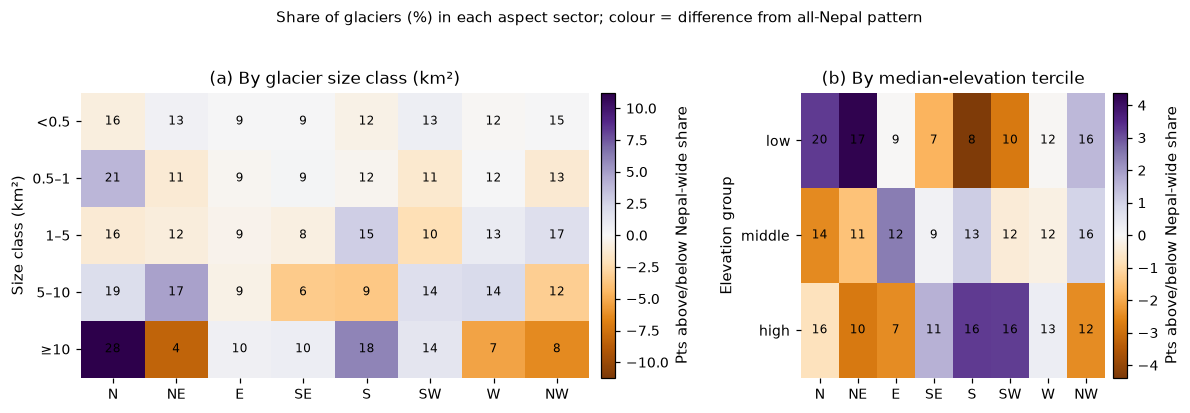

In [5]:
def row_pct(tab):
    t = tab.copy(); t.columns = SECTORS
    return 100 * t.div(t.sum(axis=1), axis=0)

p_size, p_elev = row_pct(tab_size), row_pct(tab_elev)
overall = by_sector["pct_glaciers"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [5, 3]})
for ax, P, title, ylab in zip(axes, (p_size, p_elev),
        ("(a) By glacier size class (km²)", "(b) By median-elevation tercile"),
        ("Size class (km²)", "Elevation group")):
    dev = P - overall.to_numpy()                      # percentage-point deviation from the Nepal-wide pattern
    lim = max(abs(dev.to_numpy()).max(), 1)
    im = ax.imshow(dev.to_numpy(), cmap="PuOr", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(8), SECTORS); ax.set_yticks(range(len(P)), P.index.astype(str))
    for i in range(P.shape[0]):
        for j in range(8):
            ax.text(j, i, f"{P.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
    ax.set_title(title); ax.set_ylabel(ylab)
    ax.spines[:].set_visible(False)
    cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("Pts above/below Nepal-wide share")

fig.suptitle("Share of glaciers (%) in each aspect sector; colour = difference from all-Nepal pattern", fontsize=10, y=1.03)
fig.tight_layout()
save_fig(fig, "04_aspect_by_group")
plt.show()

In [6]:
rows = []
for g, d in core.groupby("elev_grp", observed=True):
    rows.append({
        "elev_group": g, "n": len(d),
        "zmed_range_m": f"{d['zmed_m'].min():.0f}–{d['zmed_m'].max():.0f}",
        "pct_NW_N_NE": 100 * d["sector"].isin([7, 0, 1]).mean(),
        "pct_SE_S_SW": 100 * d["sector"].isin([3, 4, 5]).mean(),
        "area_w_mean_aspect_deg": circ_mean(d["aspect_deg"], d["area_km2"])[0],
        "R": circ_mean(d["aspect_deg"], d["area_km2"])[1],
    })
elev_tab = pd.DataFrame(rows).set_index("elev_group")
print(elev_tab.round(2).to_string())
elev_tab.round(3).to_csv(TAB / "aspect_by_elevation_group.csv")

               n zmed_range_m  pct_NW_N_NE  pct_SE_S_SW  area_w_mean_aspect_deg     R
elev_group                                                                           
low         1494    2654–5285        53.28        25.17                  359.11  0.26
middle      1493    5285–5629        41.19        34.96                  238.07  0.08
high        1493    5630–8116        38.25        42.26                  281.75  0.15
